# Лабораторная работа №14: Управляемая генерация изображений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Получить canny/depth/pose controls.
- Сравнить control scale и CFG.
- Использовать control как synthetic annotation для downstream model.

## Теоретическая часть

ControlNet добавляет trainable branch к замороженной diffusion model и принимает spatial condition (edges, depth, pose). В лабораторной используется готовый ControlNet; изменяются conditioning scale и CFG.

![Пример результата ControlNet с Canny-контролем](https://huggingface.co/lllyasviel/sd-controlnet-canny/resolve/main/images/bird_canny_out.png)


Готовый ControlNet добавляет пространственное условие к SD1.5. В работе контур Canny вычисляется только из train MNIST; тот же исходный label сопровождает synthetic image. Edge F1, CLIP text similarity и downstream accuracy на реальном test отражают разные свойства и могут конфликтовать.

Для контуров $F_1=2PR/(P+R)$; допустимое геометрическое отклонение задаётся расширением контуров до расчёта точности и полноты. Downstream accuracy измеряется только на реальном отложенном test.

### Экспериментальный протокол

Выбрано условие Canny, обучение ControlNet не требуется. Полный режим: 20 train контуров каждого из 10 классов, 5 генераций на контур (base + сетка scale/CFG), отдельный real test и одинаковые 500 optimizer steps каждого downstream classifier. Это дорогой эксперимент: перед запуском оцените лимит Colab, сохраняйте artifacts в Drive; FAST_DEV_RUN генерирует по 1 примеру каждого класса и 2 шага классификатора, только smoke. Нужны CUDA, diffusers transformers accelerate opencv-python torchvision.

### Материалы

- [Diffusers ControlNet](https://huggingface.co/docs/diffusers/using-diffusers/controlnet)
- [ControlNet paper](https://arxiv.org/abs/2302.05543)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [14]:
# Colab: зависимости и воспроизводимый конфиг; файлы живут в /content или в Google Drive.
%pip -q install "diffusers==0.35.2" "transformers==4.57.1" "accelerate==1.11.0" "opencv-python-headless" "scikit-learn" "safetensors" "pandas" "matplotlib"

from pathlib import Path
import os, json, random, time, gc, platform
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
FAST_DEV_RUN = False  # Сначала True; для сдачи переключить на False и выполнить Run All.
SAVE_TO_DRIVE = False  # Для полного эксперимента рекомендуется True.

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE != "cuda":
    raise RuntimeError("Нужна CUDA: Colab -> Среда выполнения -> Сменить среду -> T4 GPU")

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACTS = Path("/content/drive/MyDrive/CV_lab14_artifacts")
else:
    ARTIFACTS = Path.cwd() / "artifacts"
RUN_DIR = ARTIFACTS / ("smoke" if FAST_DEV_RUN else "full")
DATA_ROOT = Path.cwd() / "data"
for folder in (RUN_DIR, DATA_ROOT):
    folder.mkdir(parents=True, exist_ok=True)

def save_json(name, value):
    path = RUN_DIR / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
    return path

PER_CLASS = 1 if FAST_DEV_RUN else 20
INFERENCE_STEPS = 8 if FAST_DEV_RUN else 20
TRAIN_STEPS = 2 if FAST_DEV_RUN else 500
BATCH_SIZE = 64
SETTINGS = [
    {"name": "base", "scale": 1.0, "cfg": 7.5},
    {"name": "s05_g4", "scale": 0.5, "cfg": 4.0},
    {"name": "s05_g9", "scale": 0.5, "cfg": 9.0},
    {"name": "s15_g4", "scale": 1.5, "cfg": 4.0},
    {"name": "s15_g9", "scale": 1.5, "cfg": 9.0},
]
print({"gpu": torch.cuda.get_device_name(0), "fast": FAST_DEV_RUN,
       "artifacts": str(RUN_DIR), "n_images": 10 * PER_CLASS * len(SETTINGS),
       "train_steps_per_model": TRAIN_STEPS})


{'gpu': 'Tesla T4', 'fast': False, 'artifacts': '/content/artifacts/full', 'n_images': 1000, 'train_steps_per_model': 500}


### Непересекающиеся MNIST выборки

*Вес: 1 балл.*

**Постановка.** Контур и метка должны происходить из одной исходной сцены, иначе synthetic augmentation получает неверную разметку. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите только train/test MNIST, выберите реальные train индексы по классам.

**Результат.** Проверяемое состояние «Непересекающиеся MNIST выборки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите только train/test MNIST, выберите реальные train индексы по классам» и его результат доступен следующему этапу.

,digit,train_contours
0,0,20
1,1,20
2,2,20
3,3,20
4,4,20
5,5,20
6,6,20
7,7,20
8,8,20
9,9,20


Train: 60000; независимый test: 10000; контуров: 200


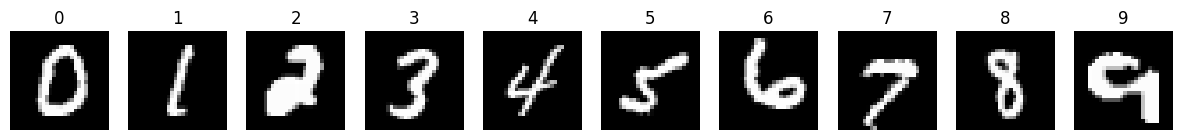

In [15]:
# Индексы для ControlNet выбираются ТОЛЬКО из train MNIST; test остаётся изолированным.
from torchvision.datasets import MNIST
from torchvision import transforms

mnist_train = MNIST(root=DATA_ROOT, train=True, download=True)
mnist_test = MNIST(root=DATA_ROOT, train=False, download=True)
labels_train = mnist_train.targets.numpy()
rng = np.random.default_rng(SEED)
selected_indices = {}
for digit in range(10):
    candidates = np.flatnonzero(labels_train == digit)
    selected_indices[digit] = rng.choice(candidates, size=PER_CLASS, replace=False).astype(int).tolist()

train_indices = [i for digit in range(10) for i in selected_indices[digit]]
assert len(train_indices) == len(set(train_indices)) == 10 * PER_CLASS
split_info = {
    "dataset": "MNIST", "source": "torchvision.datasets.MNIST", "seed": SEED,
    "train_dataset_size": len(mnist_train), "test_dataset_size": len(mnist_test),
    "train_contour_indices_by_class": {str(k): v for k, v in selected_indices.items()},
    "test_used_for_selection": False
}
save_json("mnist_split.json", split_info)
display(pd.DataFrame({"digit": range(10), "train_contours": [len(selected_indices[d]) for d in range(10)]}))
print(f"Train: {len(mnist_train)}; независимый test: {len(mnist_test)}; контуров: {len(train_indices)}")
fig, axs = plt.subplots(1, 10, figsize=(15, 2))
for d, ax in enumerate(axs):
    img, target = mnist_train[selected_indices[d][0]]
    ax.imshow(img, cmap="gray"); ax.set_title(f"{target}"); ax.axis("off")
plt.show()


### Контуры Canny и происхождение меток

*Вес: 1 балл.*

**Постановка.** Контур и метка должны происходить из одной исходной сцены, иначе synthetic augmentation получает неверную разметку. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Постройте PNG-контуры, сохраните исходные индексы, классы и фиксированные seeds.

**Результат.** Проверяемое состояние «Контуры Canny и происхождение меток» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Постройте PNG-контуры, сохраните исходные индексы, классы и фиксированные seeds» и его результат доступен следующему этапу.

/tmp/ipykernel_379/2561672083.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(np.repeat(canny[..., None], 3, axis=2), mode="RGB")


,digit,n,min_edges,mean_edges
0,0,20,194,517.00
1,1,20,56,220.50
2,2,20,178,434.15
3,3,20,243,449.55
4,4,20,85,390.80
5,5,20,154,334.45
6,6,20,135,454.65
7,7,20,67,255.00
8,8,20,257,568.55
9,9,20,136,385.50


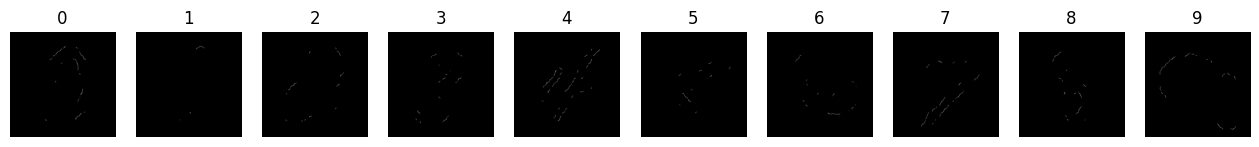

Canny manifest: /content/artifacts/full/control_manifest.json


In [16]:
# Canny строится из той же MNIST-картинки, чей класс станет меткой синтетики.
import cv2
from PIL import Image

CONTROL_SIZE = 512
control_dir = RUN_DIR / "controls"
source_dir = RUN_DIR / "sources"
control_dir.mkdir(parents=True, exist_ok=True)
source_dir.mkdir(parents=True, exist_ok=True)

def mnist_canny(mnist_image):
    gray = np.asarray(mnist_image.convert("L"), dtype=np.uint8)
    enlarged = cv2.resize(gray, (CONTROL_SIZE, CONTROL_SIZE), interpolation=cv2.INTER_CUBIC)
    canny = cv2.Canny(enlarged, 75, 150)
    return Image.fromarray(np.repeat(canny[..., None], 3, axis=2), mode="RGB")

control_records = []
for digit in range(10):
    for index in selected_indices[digit]:
        source_image, actual_label = mnist_train[index]
        assert int(actual_label) == digit
        control_path = control_dir / f"mnist_{index:05d}.png"
        source_path = source_dir / f"mnist_{index:05d}.png"
        if not control_path.exists():
            mnist_canny(source_image).save(control_path)
        if not source_path.exists():
            source_image.save(source_path)
        edge_pixels = int((np.array(Image.open(control_path).convert("L")) > 0).sum())
        assert edge_pixels > 0, f"Пустой Canny у MNIST index={index}"
        control_records.append({"source_index": int(index), "digit": int(digit),
                                "seed": int(SEED + index), "control_png": str(control_path),
                                "source_png": str(source_path), "edge_pixels": edge_pixels})
save_json("control_manifest.json", control_records)
display(pd.DataFrame(control_records).groupby("digit").agg(n=("source_index", "count"),
                                                             min_edges=("edge_pixels", "min"),
                                                             mean_edges=("edge_pixels", "mean")).reset_index())
fig, axs = plt.subplots(1, 10, figsize=(16, 2))
for d, ax in enumerate(axs):
    row = next(r for r in control_records if r["digit"] == d)
    ax.imshow(Image.open(row["control_png"])); ax.set_title(str(d)); ax.axis("off")
plt.show()
print("Canny manifest:", RUN_DIR / "control_manifest.json")


### Загрузка предобученного ControlNet

*Вес: 1 балл.*

**Постановка.** Совместное изменение силы контроля и CFG выявляет компромисс между структурой контура и текстовым условием. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите SD1.5 и Canny ControlNet с совместимым scheduler; CPU-имитация недопустима.

**Результат.** Проверяемое состояние «Загрузка предобученного ControlNet» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите SD1.5 и Canny ControlNet с совместимым scheduler; CPU-имитация недопустима» и его результат доступен следующему этапу.

In [17]:
# SD 1.5 + Canny ControlNet запускаются на GPU; UniPC ускоряет денойзинг.
from diffusers import ControlNetModel, StableDiffusionControlNetPipeline, UniPCMultistepScheduler
import diffusers, transformers, accelerate, torchvision

SD_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CONTROLNET_ID = "lllyasviel/sd-controlnet-canny"
controlnet = ControlNetModel.from_pretrained(CONTROLNET_ID, torch_dtype=torch.float16,
                                             use_safetensors=True)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    SD_ID, controlnet=controlnet, torch_dtype=torch.float16, use_safetensors=True,
    safety_checker=None, requires_safety_checker=False,
)
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
pipe.enable_model_cpu_offload()  # Меньше VRAM на Colab T4, без CPU-имитации вычислений.
pipe.set_progress_bar_config(disable=True)

config = {
    "seed": SEED, "fast_dev_run": FAST_DEV_RUN, "per_class": PER_CLASS,
    "inference_steps": INFERENCE_STEPS, "image_size": CONTROL_SIZE,
    "settings": SETTINGS, "sd_model": SD_ID, "controlnet_model": CONTROLNET_ID,
    "scheduler": pipe.scheduler.__class__.__name__, "dtype": "float16",
    "cuda_device": torch.cuda.get_device_name(0),
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "torchvision": torchvision.__version__, "diffusers": diffusers.__version__,
                 "transformers": transformers.__version__, "accelerate": accelerate.__version__,
                 "opencv": cv2.__version__},
    "sources": {"MNIST": "torchvision MNIST (original MNIST dataset)",
                "SD1.5": SD_ID, "ControlNet": CONTROLNET_ID},
    "licenses": {"SD1.5": "CreativeML OpenRAIL-M", "ControlNet": "OpenRAIL"}
}
save_json("experiment_config.json", config)
display(pd.DataFrame([{"model": "SD 1.5", "id": SD_ID},
                      {"model": "ControlNet Canny", "id": CONTROLNET_ID}]))
print("Scheduler:", config["scheduler"], "GPU:", config["cuda_device"])


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

,model,id
0,SD 1.5,stable-diffusion-v1-5/stable-diffusion-v1-5
1,ControlNet Canny,lllyasviel/sd-controlnet-canny


Scheduler: UniPCMultistepScheduler GPU: Tesla T4


### Факторная сетка генераций

*Вес: 1 балл.*

**Постановка.** Совместное изменение силы контроля и CFG выявляет компромисс между структурой контура и текстовым условием. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните baseline и все сочетания силы контроля и CFG на одинаковых входах и seeds.

**Результат.** Проверяемое состояние «Факторная сетка генераций» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните baseline и все сочетания силы контроля и CFG на одинаковых входах и seeds» и его результат доступен следующему этапу.

ControlNet generation:   0%|          | 0/200 [00:00<?, ?it/s]

,setting,n,total_seconds,mean_seconds
0,base,200,1410.61,7.05
1,s05_g4,200,1413.83,7.07
2,s05_g9,200,1412.35,7.06
3,s15_g4,200,1412.38,7.06
4,s15_g9,200,1411.43,7.06


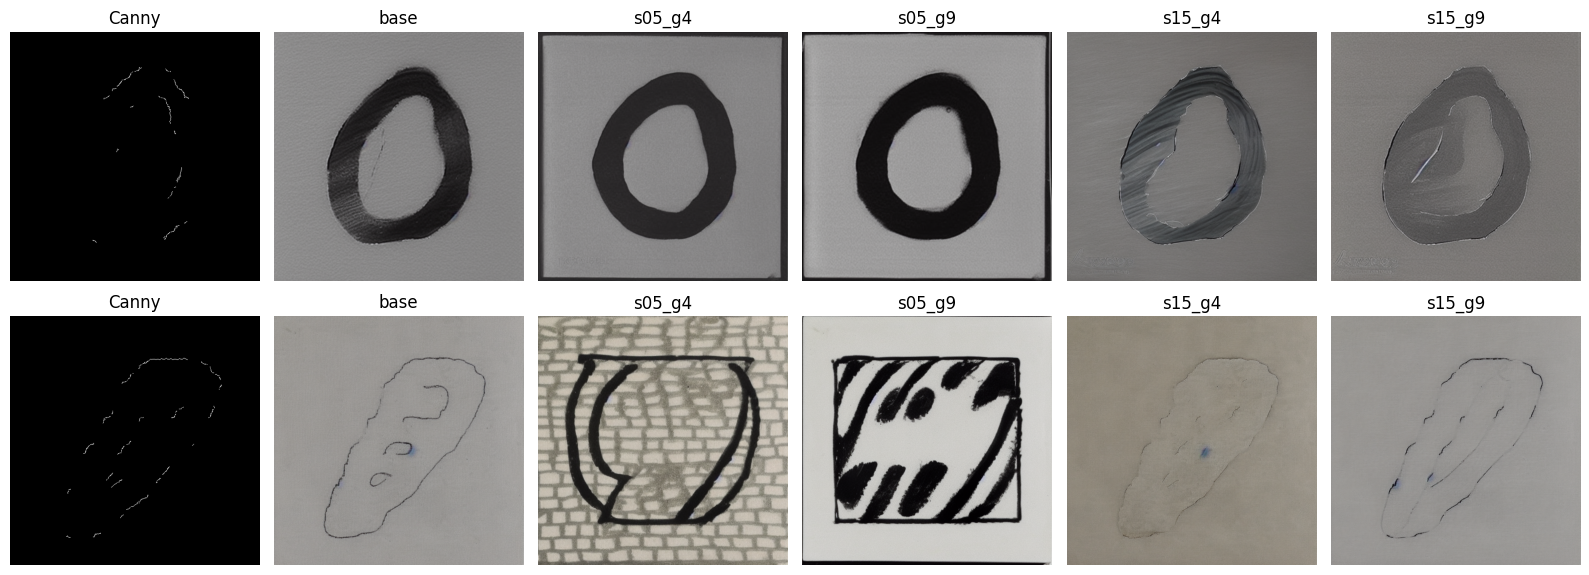

Фактически сохранено генераций: 1000


In [18]:
# Пять конфигураций для каждого контура: один prompt и один seed, меняются лишь scale/CFG.
from tqdm.auto import tqdm

image_dir = RUN_DIR / "generated"
image_dir.mkdir(parents=True, exist_ok=True)
manifest_path = RUN_DIR / "generation_manifest.json"
if manifest_path.exists():
    cached_records = json.loads(manifest_path.read_text(encoding="utf-8"))
else:
    cached_records = []
cache = {r["id"]: r for r in cached_records}

def digit_prompt(digit):
    return (f"A single handwritten digit {digit}, black ink on a pure white background, "
            "centered, isolated, high contrast, simple MNIST-like numeral, no decorations")

NEGATIVE_PROMPT = "multiple digits, letters, words, landscape, people, complex background, watermark"
for source in tqdm(control_records, desc="ControlNet generation"):
    control_image = Image.open(source["control_png"]).convert("RGB")
    for setting in SETTINGS:
        image_id = f"{source['source_index']:05d}_{setting['name']}"
        destination = image_dir / f"{image_id}.png"
        if image_id in cache and destination.exists():
            continue
        t0 = time.perf_counter()
        generator = torch.Generator(device="cpu").manual_seed(source["seed"])
        with torch.inference_mode():
            result = pipe(prompt=digit_prompt(source["digit"]),
                          negative_prompt=NEGATIVE_PROMPT,
                          image=control_image,
                          width=CONTROL_SIZE, height=CONTROL_SIZE,
                          num_inference_steps=INFERENCE_STEPS,
                          guidance_scale=setting["cfg"],
                          controlnet_conditioning_scale=setting["scale"],
                          generator=generator).images[0]
        result.save(destination)
        cache[image_id] = {
            "id": image_id, "source_index": source["source_index"], "digit": source["digit"],
            "seed": source["seed"], "setting": setting["name"],
            "scale": setting["scale"], "cfg": setting["cfg"],
            "prompt": digit_prompt(source["digit"]), "generated_png": str(destination),
            "control_png": source["control_png"], "elapsed_s": round(time.perf_counter() - t0, 3)
        }
        # Покадровый checkpoint позволяет продолжить после прерывания Colab.
        save_json("generation_manifest.json", list(cache.values()))

generation_records = sorted(cache.values(), key=lambda x: (x["source_index"], x["setting"]))
assert len(generation_records) == len(control_records) * len(SETTINGS)
# Не допускаем, чтобы старый кэш другого режима попал в текущие метрики.
assert all(Path(x["generated_png"]).exists() for x in generation_records)
save_json("generation_manifest.json", generation_records)
gen_summary = pd.DataFrame(generation_records).groupby("setting").agg(
    n=("id", "count"), total_seconds=("elapsed_s", "sum"),
    mean_seconds=("elapsed_s", "mean")).reset_index()
display(gen_summary.round(2))

fig, axs = plt.subplots(2, len(SETTINGS) + 1, figsize=(16, 6))
for row_idx, src in enumerate(control_records[:2]):
    axs[row_idx, 0].imshow(Image.open(src["control_png"])); axs[row_idx, 0].set_title("Canny")
    for col_idx, setting in enumerate(SETTINGS, start=1):
        rec = cache[f"{src['source_index']:05d}_{setting['name']}"]
        axs[row_idx, col_idx].imshow(Image.open(rec["generated_png"]))
        axs[row_idx, col_idx].set_title(setting["name"])
    for ax in axs[row_idx]: ax.axis("off")
plt.tight_layout()
plt.savefig(RUN_DIR / "generation_grid.png", dpi=140)
plt.show()
print("Фактически сохранено генераций:", len(generation_records))


### Структурное и текстовое соответствие

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Из реальных PNG рассчитайте edge F1 с допуском и CLIP text-image cosine.

**Результат.** Проверяемое состояние «Структурное и текстовое соответствие» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Из реальных PNG рассчитайте edge F1 с допуском и CLIP text-image cosine» и его результат доступен следующему этапу.

CLIP and edge metrics:   0%|          | 0/125 [00:00<?, ?it/s]

,setting,scale,cfg,n,edge_f1_mean,clip_cosine_mean,elapsed_s_sum
0,base,1.0,7.5,200,0.2776,0.2932,1410.611
1,s05_g4,0.5,4.0,200,0.0913,0.2918,1413.829
2,s05_g9,0.5,9.0,200,0.0904,0.3130,1412.351
3,s15_g4,1.5,4.0,200,0.4867,0.2472,1412.383
4,s15_g9,1.5,9.0,200,0.4266,0.2697,1411.432


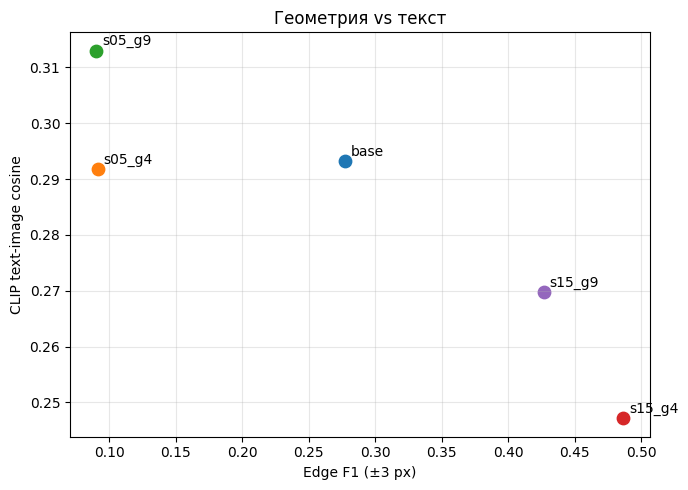

Измерено реальных PNG: 1000


In [19]:
# Edge F1 измеряет геометрию с допуском; CLIP cosine — только близость картинки к тексту.
from transformers import CLIPModel, CLIPProcessor
import torch.nn.functional as F

# Модель генерации не требуется для расчёта метрик: освобождаем GPU перед CLIP.
del pipe, controlnet
gc.collect(); torch.cuda.empty_cache()
CLIP_ID = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_ID)

def tolerant_edge_f1(control_png, generated_png, radius=3):
    target = cv2.imread(str(control_png), cv2.IMREAD_GRAYSCALE)
    generated = cv2.imread(str(generated_png), cv2.IMREAD_GRAYSCALE)
    assert target is not None and generated is not None
    edges_true = target > 127
    edges_pred = cv2.Canny(generated, 100, 200) > 0
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * radius + 1,) * 2)
    true_dilated = cv2.dilate(edges_true.astype(np.uint8), kernel) > 0
    pred_dilated = cv2.dilate(edges_pred.astype(np.uint8), kernel) > 0
    precision = float(np.logical_and(edges_pred, true_dilated).sum() / max(1, edges_pred.sum()))
    recall = float(np.logical_and(edges_true, pred_dilated).sum() / max(1, edges_true.sum()))
    return 2 * precision * recall / max(1e-12, precision + recall), precision, recall

metrics_records = []
for start in tqdm(range(0, len(generation_records), 8), desc="CLIP and edge metrics"):
    batch = generation_records[start:start + 8]
    imgs = [Image.open(r["generated_png"]).convert("RGB") for r in batch]
    inputs = clip_processor(text=[r["prompt"] for r in batch], images=imgs,
                            return_tensors="pt", padding=True, truncation=True)
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    with torch.inference_mode():
        output = clip_model(**inputs)
        image_embeds = F.normalize(output.image_embeds.float(), dim=-1)
        text_embeds = F.normalize(output.text_embeds.float(), dim=-1)
        similarities = (image_embeds * text_embeds).sum(-1).cpu().tolist()
    for rec, similarity in zip(batch, similarities):
        f1, precision, recall = tolerant_edge_f1(rec["control_png"], rec["generated_png"])
        metrics_records.append({**rec, "edge_f1": f1, "edge_precision": precision,
                                "edge_recall": recall, "clip_cosine": float(similarity)})
metrics_df = pd.DataFrame(metrics_records)
metrics_df.to_csv(RUN_DIR / "per_image_metrics.csv", index=False)
setting_metrics = metrics_df.groupby(["setting", "scale", "cfg"], as_index=False).agg(
    n=("id", "size"), edge_f1_mean=("edge_f1", "mean"),
    clip_cosine_mean=("clip_cosine", "mean"), elapsed_s_sum=("elapsed_s", "sum"))
setting_metrics.to_csv(RUN_DIR / "settings_metrics.csv", index=False)
display(setting_metrics.round(4))
fig, ax = plt.subplots(figsize=(7, 5))
for _, row in setting_metrics.iterrows():
    ax.scatter(row["edge_f1_mean"], row["clip_cosine_mean"], s=80)
    ax.annotate(row["setting"], (row["edge_f1_mean"], row["clip_cosine_mean"]), xytext=(4, 4), textcoords="offset points")
ax.set(xlabel="Edge F1 (±3 px)", ylabel="CLIP text-image cosine", title="Геометрия vs текст")
ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RUN_DIR / "edge_vs_clip.png", dpi=140); plt.show()
print("Измерено реальных PNG:", len(metrics_df))


### Разнообразие внутри класса

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте попарные различия изображений внутри одного класса и настройки.

**Результат.** Проверяемое состояние «Разнообразие внутри класса» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте попарные различия изображений внутри одного класса и настройки» и его результат доступен следующему этапу.

setting,base,s05_g4,s05_g9,s15_g4,s15_g9
digit,,,,,
0,0.1228,0.1665,0.2413,0.0902,0.0895
1,0.1096,0.1572,0.1947,0.0933,0.1031
2,0.1244,0.1333,0.2032,0.0967,0.0994
3,0.1555,0.1955,0.2669,0.1028,0.0984
4,0.1052,0.1640,0.2149,0.0918,0.0864
5,0.1361,0.1746,0.2366,0.1127,0.1245
6,0.1037,0.1299,0.1578,0.0889,0.0953
7,0.1436,0.1872,0.2369,0.0969,0.1089
8,0.1128,0.1707,0.2332,0.0913,0.0986


,setting,valid_classes,mean_pairwise_mae
0,base,10,0.1271
1,s05_g4,10,0.1697
2,s05_g9,10,0.2249
3,s15_g4,10,0.0988
4,s15_g9,10,0.1031


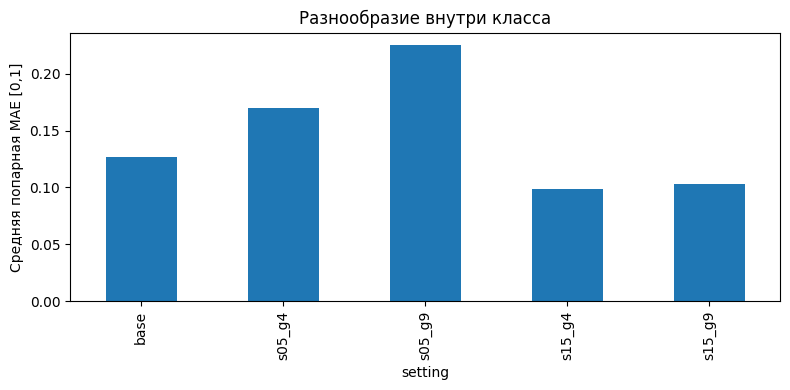

In [20]:
# Внутриклассовое разнообразие: средняя попарная пиксельная разница (MAE) для одной настройки.
from itertools import combinations

def grayscale_small(path, side=64):
    with Image.open(path) as im:
        return np.asarray(im.convert("L").resize((side, side)), dtype=np.float32) / 255.0

diversity_records = []
for (digit, setting), group in metrics_df.groupby(["digit", "setting"]):
    pixels = [grayscale_small(p) for p in group["generated_png"]]
    differences = [float(np.mean(np.abs(a - b))) for a, b in combinations(pixels, 2)]
    diversity_records.append({"digit": int(digit), "setting": setting,
                              "n_images": len(pixels), "n_pairs": len(differences),
                              "pairwise_mae": float(np.mean(differences)) if differences else np.nan})
diversity_df = pd.DataFrame(diversity_records)
diversity_df.to_csv(RUN_DIR / "diversity_by_class.csv", index=False)
display(diversity_df.pivot(index="digit", columns="setting", values="pairwise_mae").round(4))
diversity_overall = diversity_df.groupby("setting", as_index=False).agg(
    valid_classes=("pairwise_mae", "count"), mean_pairwise_mae=("pairwise_mae", "mean"))
display(diversity_overall.round(4))
if FAST_DEV_RUN:
    print("SMOKE: по одному изображению на класс/настройку; попарная MAE не определена (NaN), это ожидаемо.")
else:
    ax = diversity_overall.plot.bar(x="setting", y="mean_pairwise_mae", legend=False,
                                     figsize=(8, 4), title="Разнообразие внутри класса")
    ax.set_ylabel("Средняя попарная MAE [0,1]"); plt.tight_layout()
    plt.savefig(RUN_DIR / "diversity.png", dpi=140); plt.show()


### Аудит худших случаев

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните построчные измерения и пять наихудших примеров, не приписывая им вымышленные оценки.

**Результат.** Проверяемое состояние «Аудит худших случаев» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните построчные измерения и пять наихудших примеров, не приписывая им вымышленные оценки» и его результат доступен следующему этапу.

,id,digit,setting,edge_f1,clip_cosine,generated_png
246,16112_s05_g4,5,s05_g4,0.0,0.2274,/content/artifacts/full/generated/16112_s05_g4...
90,05627_base,0,base,0.0,0.2303,/content/artifacts/full/generated/05627_base.png
695,42047_base,5,base,0.0,0.2342,/content/artifacts/full/generated/42047_base.png
557,33771_s05_g9,8,s05_g9,0.0,0.2433,/content/artifacts/full/generated/33771_s05_g9...
79,05526_s15_g9,5,s15_g9,0.0,0.2452,/content/artifacts/full/generated/05526_s15_g9...


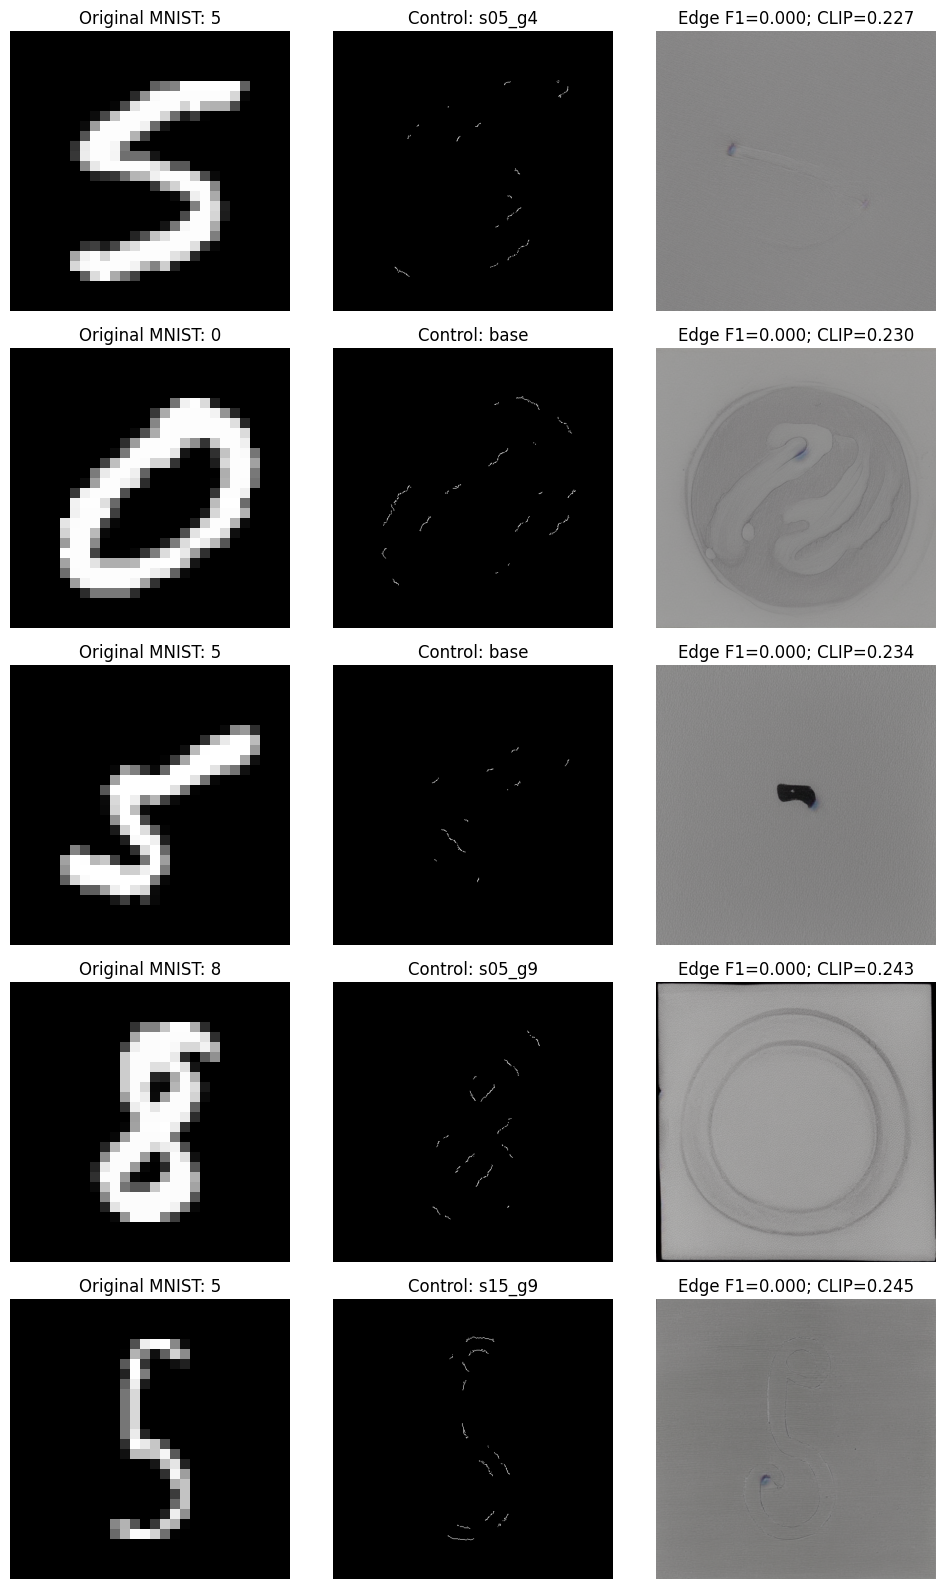

Построчные измерения: /content/artifacts/full/per_image_metrics.csv


In [21]:
# Аудитируем худшие реальные генерации по Edge F1, не приписывая им субъективные оценки.
worst_five = metrics_df.sort_values(["edge_f1", "clip_cosine"], ascending=[True, True]).head(5)
worst_five.to_csv(RUN_DIR / "worst_five.csv", index=False)
display(worst_five[["id", "digit", "setting", "edge_f1", "clip_cosine", "generated_png"]].round(4))

fig, axs = plt.subplots(5, 3, figsize=(10, 16))
for axes, (_, rec) in zip(axs, worst_five.iterrows()):
    axes[0].imshow(Image.open(next(r["source_png"] for r in control_records
                                  if r["source_index"] == rec["source_index"])).convert("L"), cmap="gray")
    axes[1].imshow(Image.open(rec["control_png"]))
    axes[2].imshow(Image.open(rec["generated_png"]))
    axes[0].set_title(f"Original MNIST: {rec['digit']}")
    axes[1].set_title(f"Control: {rec['setting']}")
    axes[2].set_title(f"Edge F1={rec['edge_f1']:.3f}; CLIP={rec['clip_cosine']:.3f}")
    for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(RUN_DIR / "five_worst_examples.png", dpi=130)
plt.show()
print("Построчные измерения:", RUN_DIR / "per_image_metrics.csv")


### Архитектура downstream-классификатора

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите CNN и фиксированную реальную обучающую подвыборку.

**Результат.** Проверяемое состояние «Архитектура downstream-классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите CNN и фиксированную реальную обучающую подвыборку» и его результат доступен следующему этапу.

In [22]:
# Маленькая CNN и фиксированная подвыборка реальных MNIST: одинаковая основа двух веток.
from torch import nn
from torch.utils.data import Dataset, Subset, ConcatDataset, DataLoader
from PIL import ImageOps

MNIST_MEAN, MNIST_STD = 0.1307, 0.3081
mnist_transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize((MNIST_MEAN,), (MNIST_STD,))
])
train_with_transform = MNIST(root=DATA_ROOT, train=True, download=True, transform=mnist_transform)
test_with_transform = MNIST(root=DATA_ROOT, train=False, download=True, transform=mnist_transform)

# Две модели видят одинаковые 100 (или 10 в smoke) реальных train примеров каждого класса.
REAL_PER_CLASS = 10 if FAST_DEV_RUN else 100
rng_real = np.random.default_rng(SEED + 1)
real_indices = []
for d in range(10):
    selected = set(selected_indices[d])
    extra_count = max(0, REAL_PER_CLASS - len(selected))
    extra = rng_real.choice([i for i in np.flatnonzero(labels_train == d) if i not in selected],
                            size=extra_count, replace=False).astype(int).tolist()
    real_indices.extend(selected_indices[d] + extra)
real_dataset = Subset(train_with_transform, real_indices)

class SyntheticMNIST(Dataset):
    def __init__(self, records):
        self.rows = records
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, idx):
        row = self.rows[idx]
        with Image.open(row["generated_png"]) as im:
            # SD генерирует чёрные цифры на белом; MNIST — светлые цифры на чёрном.
            image = ImageOps.invert(im.convert("L")).resize((28, 28), Image.Resampling.LANCZOS)
        return mnist_transform(image), int(row["digit"])

# Фиксируем base заранее; не выбираем настройку по запрещённому test.
synthetic_records = [r for r in generation_records if r["setting"] == "base"]
synthetic_dataset = SyntheticMNIST(synthetic_records)
augmented_dataset = ConcatDataset([real_dataset, synthetic_dataset])

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * 7 * 7, 128),
                                        nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

save_json("classifier_config.json", {
    "real_per_class": REAL_PER_CLASS, "real_train_indices": real_indices,
    "synthetic_setting": "base", "synthetic_count": len(synthetic_dataset),
    "seed_init_each": SEED, "batch_size": BATCH_SIZE, "steps_per_model": TRAIN_STEPS,
    "optimizer": "Adam(lr=0.001)", "augmentation_fraction_per_batch": 0.5,
    "test": "all 10000 real MNIST test samples"})
display(pd.DataFrame([{"dataset": "real train", "n": len(real_dataset)},
                      {"dataset": "synthetic train (base)", "n": len(synthetic_dataset)},
                      {"dataset": "real test", "n": len(test_with_transform)}]))
print("CNN parameters:", sum(p.numel() for p in DigitCNN().parameters()))


,dataset,n
0,real train,1000
1,synthetic train (base),200
2,real test,10000


CNN parameters: 206922


### Равнобюджетное обучение с аугментацией

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите real-only и real+synthetic варианты с одинаковым числом обновлений.

**Результат.** Проверяемое состояние «Равнобюджетное обучение с аугментацией» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите real-only и real+synthetic варианты с одинаковым числом обновлений» и его результат доступен следующему этапу.

real_only: step=50/500, mean loss (last 50)=1.1412
real_only: step=100/500, mean loss (last 50)=0.3342
real_only: step=150/500, mean loss (last 50)=0.1694
real_only: step=200/500, mean loss (last 50)=0.1019
real_only: step=250/500, mean loss (last 50)=0.0714
real_only: step=300/500, mean loss (last 50)=0.0419
real_only: step=350/500, mean loss (last 50)=0.0365
real_only: step=400/500, mean loss (last 50)=0.0243
real_only: step=450/500, mean loss (last 50)=0.0158
real_only: step=500/500, mean loss (last 50)=0.0109
real_only: 500 optimizer steps; 8.2 sec
real_plus_synthetic: step=50/500, mean loss (last 50)=1.7781
real_plus_synthetic: step=100/500, mean loss (last 50)=1.0962
real_plus_synthetic: step=150/500, mean loss (last 50)=0.8845
real_plus_synthetic: step=200/500, mean loss (last 50)=0.7414
real_plus_synthetic: step=250/500, mean loss (last 50)=0.5655
real_plus_synthetic: step=300/500, mean loss (last 50)=0.4764
real_plus_synthetic: step=350/500, mean loss (last 50)=0.4050
real_plu

,variant,steps,elapsed_s,final_loss
0,real_only,500,8.159,0.003
1,real_plus_synthetic,500,201.070,0.260


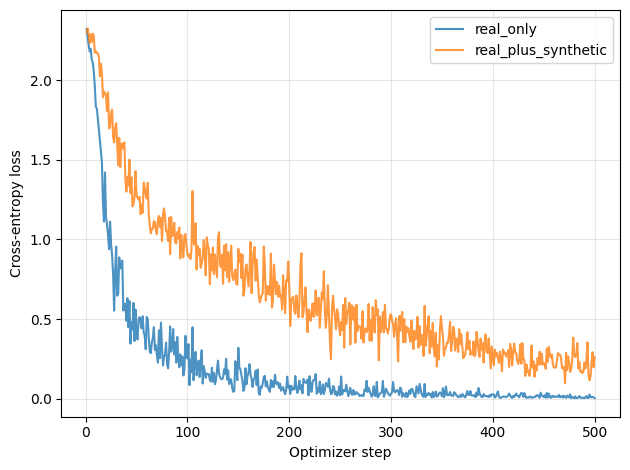

In [23]:
# Равный бюджет 500/500 шагов; фиксируем одинаковую инициализацию CNN для двух условий.
from torch.utils.data import Sampler

class FixedBatchSampler(Sampler):
    def __init__(self, batches, start_step=0):
        self.batches, self.start_step = batches, start_step
    def __iter__(self):
        for row in self.batches[self.start_step:]:
            yield [int(x) for x in row]
    def __len__(self):
        return len(self.batches) - self.start_step

# Детерминированный план мини-батчей повторяется при возобновлении с checkpoint.
real_plan = np.random.default_rng(SEED + 101).integers(
    0, len(real_dataset), size=(TRAIN_STEPS, BATCH_SIZE), endpoint=False)
synth_plan = np.random.default_rng(SEED + 102).integers(
    0, len(synthetic_dataset), size=(TRAIN_STEPS, BATCH_SIZE // 2), endpoint=False)
aug_plan = np.concatenate([real_plan[:, :BATCH_SIZE // 2],
                           synth_plan + len(real_dataset)], axis=1)
order_rng = np.random.default_rng(SEED + 103)
for batch in aug_plan:
    order_rng.shuffle(batch)

models_dir = RUN_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Сохраняем не только веса, но и optimizer/step, чтобы Colab мог продолжить с прерванного шага.
def train_variant(name, dataset, batches):
    seed_everything(SEED)
    model = DigitCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    checkpoint_path = models_dir / f"{name}.pt"
    losses, start_step, seconds_before = [], 0, 0.0
    if checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        losses = checkpoint["losses"]
        start_step = checkpoint["step"]
        seconds_before = checkpoint.get("elapsed_s", 0.0)
    loader = DataLoader(dataset, batch_sampler=FixedBatchSampler(batches, start_step),
                        num_workers=0, pin_memory=torch.cuda.is_available())
    model.train()
    tic = time.perf_counter()
    for step, (images, targets) in enumerate(loader, start=start_step + 1):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(images), targets)
        loss.backward()
        optimizer.step()
        losses.append(float(loss.detach().cpu()))
        if step % 50 == 0 or step == TRAIN_STEPS:
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                        "step": step, "losses": losses,
                        "elapsed_s": seconds_before + time.perf_counter() - tic}, checkpoint_path)
            print(f"{name}: step={step}/{TRAIN_STEPS}, mean loss (last 50)={np.mean(losses[-50:]):.4f}")
    total_time = seconds_before + time.perf_counter() - tic
    print(f"{name}: {len(losses)} optimizer steps; {total_time:.1f} sec")
    model.cpu(); del model, optimizer
    torch.cuda.empty_cache()
    return {"variant": name, "steps": len(losses), "elapsed_s": total_time,
            "final_loss": losses[-1], "losses": losses}

real_log = train_variant("real_only", real_dataset, real_plan)
aug_log = train_variant("real_plus_synthetic", augmented_dataset, aug_plan)
assert real_log["steps"] == aug_log["steps"] == TRAIN_STEPS
training_logs = [real_log, aug_log]
save_json("training_history.json", training_logs)
display(pd.DataFrame([{k: x[k] for k in ("variant", "steps", "elapsed_s", "final_loss")}
                      for x in training_logs]).round(3))
for log in training_logs:
    plt.plot(range(1, len(log["losses"]) + 1), log["losses"], label=log["variant"], alpha=.8)
plt.xlabel("Optimizer step"); plt.ylabel("Cross-entropy loss"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RUN_DIR / "training_loss.png", dpi=140); plt.show()


### Сравнение на реальном test

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните точность по классам и confusion matrices на независимом real test.

**Результат.** Проверяемое состояние «Сравнение на реальном test» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните точность по классам и confusion matrices на независимом real test» и его результат доступен следующему этапу.

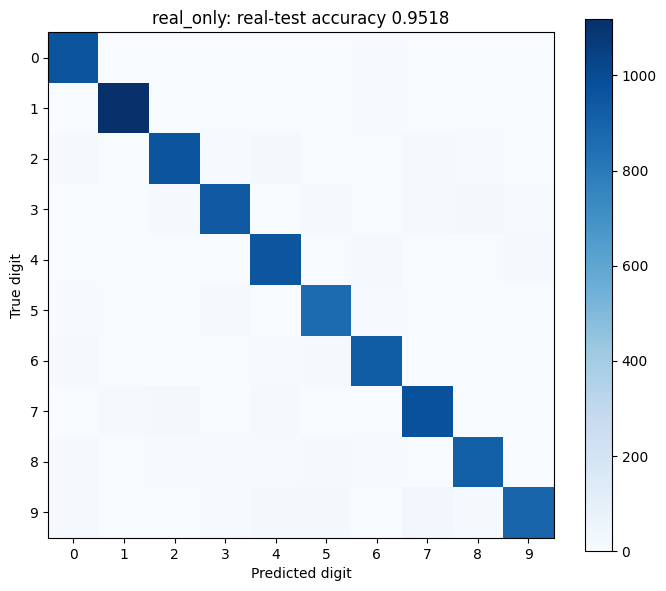

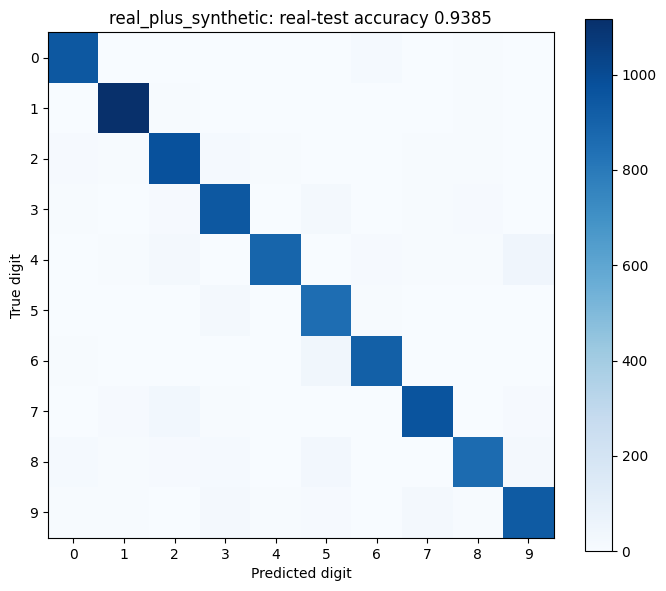

,variant,test_accuracy,steps,n_real_test
0,real_only,0.9518,500,10000
1,real_plus_synthetic,0.9385,500,10000


variant,real_only,real_plus_synthetic
digit,,
0,0.9857,0.9653
1,0.9859,0.9841
2,0.9331,0.9457
3,0.9307,0.9337
4,0.9705,0.9053
5,0.9686,0.9563
6,0.9645,0.9489
7,0.9523,0.9339
8,0.9405,0.8830


Accuracy difference (aug - real): -0.0133
FAST_DEV_RUN = False ; smoke-метрики не подходят для итоговых выводов.


In [24]:
# Оцениваем обе CNN только на исходном real MNIST test; результаты и матрицы видны прямо здесь.
from sklearn.metrics import accuracy_score, confusion_matrix

real_test_loader = DataLoader(test_with_transform, batch_size=256, shuffle=False,
                              num_workers=0, pin_memory=torch.cuda.is_available())

def evaluate_variant(name):
    checkpoint = torch.load(models_dir / f"{name}.pt", map_location="cpu", weights_only=False)
    model = DigitCNN().to(DEVICE)
    model.load_state_dict(checkpoint["model"])
    model.eval()
    y_true, y_pred = [], []
    with torch.inference_mode():
        for images, labels in real_test_loader:
            predictions = model(images.to(DEVICE, non_blocking=True)).argmax(dim=1).cpu()
            y_true.extend(labels.tolist())
            y_pred.extend(predictions.tolist())
    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    per_class = cm.diagonal() / np.maximum(1, cm.sum(axis=1))
    result = {"variant": name, "test_accuracy": float(accuracy_score(y_true, y_pred)),
              "steps": checkpoint["step"], "n_real_test": len(y_true)}
    model.cpu(); del model
    torch.cuda.empty_cache()
    return result, cm, per_class

results, matrices, class_rows = [], {}, []
for name in ("real_only", "real_plus_synthetic"):
    result, cm, per_class = evaluate_variant(name)
    results.append(result); matrices[name] = cm
    class_rows.extend({"variant": name, "digit": d, "accuracy": float(v),
                       "n_test": int(cm[d].sum())} for d, v in enumerate(per_class))
    pd.DataFrame(cm, index=range(10), columns=range(10)).to_csv(RUN_DIR / f"confusion_{name}.csv")
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, cmap="Blues")
    fig.colorbar(im, ax=ax)
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set(xlabel="Predicted digit", ylabel="True digit", title=f"{name}: real-test accuracy {result['test_accuracy']:.4f}")
    plt.tight_layout(); plt.savefig(RUN_DIR / f"confusion_{name}.png", dpi=140); plt.show()

result_df = pd.DataFrame(results)
class_df = pd.DataFrame(class_rows)
result_df.to_csv(RUN_DIR / "real_test_summary.csv", index=False)
class_df.to_csv(RUN_DIR / "accuracy_per_class.csv", index=False)
save_json("real_test_summary.json", results)
display(result_df.round(4))
display(class_df.pivot(index="digit", columns="variant", values="accuracy").round(4))
print("Accuracy difference (aug - real):",
      round(results[1]["test_accuracy"] - results[0]["test_accuracy"], 4))
print("FAST_DEV_RUN =", FAST_DEV_RUN, "; smoke-метрики не подходят для итоговых выводов.")


### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.


## Анализ результатов

### 1. Сравнение ControlNet

Полный эксперимент: 200 контуров MNIST, 5 конфигураций, 1000 генераций, seed=42, 20 inference steps.

| Конфигурация | Edge F1 ↑ | CLIP ↑ | Diversity ↑ | Время, с |
|---|---:|---:|---:|---:|
| Base (1.0 / 7.5) | 0.2776 | 0.2932 | 0.1271 | 1410.6 |
| Scale 0.5 / CFG 4 | 0.0913 | 0.2918 | 0.1697 | 1413.8 |
| Scale 0.5 / CFG 9 | 0.0904 | **0.3130** | **0.2249** | 1412.4 |
| Scale 1.5 / CFG 4 | **0.4867** | 0.2472 | 0.0988 | 1412.4 |
| Scale 1.5 / CFG 9 | 0.4266 | 0.2697 | 0.1031 | 1411.4 |

- Увеличение Control Scale улучшает геометрию: Edge F1 достигает **0.4867**, но снижает разнообразие.
- При Scale=0.5 увеличение CFG с 4 до 9 повышает CLIP с 0.2918 до 0.3130.
- Максимальное геометрическое соответствие не совпадает с максимальной текстовой близостью.
- Время генерации практически одинаковое: около 7.06 с/изображение.

### 2. Анализ пяти неудачных генераций

| ID | Класс | Edge F1 | Наблюдаемая проблема |
|---|---:|---:|---|
| 16112_s05_g4 | 5 | 0.000 | Цифра почти исчезла; слабый контроль, разреженный контур. |
| 05627_base | 0 | 0.000 | Посторонние округлые структуры вместо цифры. |
| 42047_base | 5 | 0.000 | Только короткий тёмный фрагмент вместо пятёрки. |
| 33771_s05_g9 | 8 | 0.000 | Окружности вместо восьмёрки; потеря структуры. |
| 05526_s15_g9 | 5 | 0.000 | Едва заметная цифра; крайне низкий контраст. |

Основные ограничения: фрагментированные Canny-контуры, артефакты генерации и отсутствие гарантии сохранения исходной метки. Edge F1 и CLIP не измеряют правильность класса напрямую.

### 3. Downstream-классификация

Обе CNN обучены 500 шагов с одинаковой начальной инициализацией. Проверка выполнена на 10 000 реальных изображений MNIST.

| Показатель | Real-only | Real + Synthetic |
|---|---:|---:|
| Train loss, последний шаг | 0.003 | 0.260 |
| Test accuracy | **95.18%** | 93.85% |
| Обучение, с | 8.2 | 201.1 |

- Добавление 200 синтетических изображений снизило accuracy на **1.33 п.п.**
- На классе 9 точность выросла с 88.60% до 92.37%, но на классе 4 снизилась с 97.05% до 90.53%.
- Обе кривые loss убывают; обучение устойчивое.
- Augmented-модель использовала 32 реальных и 32 синтетических примера вместо 64 реальных на шаг, поэтому эффект качества синтетики не полностью изолирован.



## Выводы

1. ControlNet позволяет управлять геометрией генерации: увеличение Scale повышает Edge F1 до **0.4867**.
2. Сильный геометрический контроль ограничивает разнообразие: MAE снижается до **0.0988**.
3. Максимальный CLIP (**0.3130**) не гарантирует правильную форму цифры.
4. Синтетическая аугментация снизила accuracy с **95.18% до 93.85%**. Вероятные факторы — дефекты генерации и изменение доли реальных примеров в батче.
5. Качество синтетических данных необходимо оценивать не только по изображениям, но и по результатам downstream-модели на независимом тесте.
